# Data Cleaning and Visualization – Titanic Dataset

**Objective:** Clean the Titanic passenger dataset, explore its structure, handle missing values and duplicates, inspect outliers, and create visualizations.

**Tools:** Python, Pandas, NumPy, Matplotlib, Jupyter Notebook.

> Run the cells from top to bottom. This notebook expects `titanic.csv` in the project's `data/` folder. If it is not found, it will try to download the public dataset.

## 1. Import libraries and set up project paths

In [1]:
from pathlib import Path
import urllib.request

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Find the project root whether this notebook is run from notebooks/ or the root folder.
cwd = Path.cwd()
if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "output"
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Data folder:", DATA_DIR)
print("Output folder:", OUTPUT_DIR)

Project folder: /mnt/data
Data folder: /mnt/data/data
Output folder: /mnt/data/output


## 2. Load the dataset

In [2]:
data_path = DATA_DIR / "titanic.csv"

if not data_path.exists():
    dataset_url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    print("Local dataset not found. Downloading Titanic dataset...")
    urllib.request.urlretrieve(dataset_url, data_path)

df = pd.read_csv(data_path)
print("Dataset loaded successfully.")
display(df.head())

Dataset loaded successfully.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Understand the data

In [3]:
print("Dataset shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe())

Dataset shape (rows, columns): (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Numerical summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 4. Check missing values and duplicates

In [4]:
missing_values = df.isnull().sum().sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2)
})
display(missing_summary)

print("Duplicate rows:", df.duplicated().sum())

,Missing Values,Missing Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


Duplicate rows: 0


## 5. Clean the dataset

- Fill missing `Age` values with the median.
- Fill missing `Embarked` values with the mode.
- Fill missing `Cabin` values with the label `Unknown`.
- Remove duplicate rows.

The median is used for `Age` because it is less affected by extreme values than the mean. `Cabin` has many missing values, so missing entries are kept as an explicit category.

In [5]:
cleaned_df = df.copy()

cleaned_df["Age"] = cleaned_df["Age"].fillna(cleaned_df["Age"].median())
cleaned_df["Embarked"] = cleaned_df["Embarked"].fillna(cleaned_df["Embarked"].mode()[0])
cleaned_df["Cabin"] = cleaned_df["Cabin"].fillna("Unknown")

rows_before = len(cleaned_df)
cleaned_df = cleaned_df.drop_duplicates().copy()
duplicates_removed = rows_before - len(cleaned_df)

print("Duplicate rows removed:", duplicates_removed)
print("\nMissing values after cleaning:")
display(cleaned_df.isnull().sum().to_frame("Missing Values"))

Duplicate rows removed: 0

Missing values after cleaning:


,Missing Values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## 6. Detect outliers using the IQR method

The Interquartile Range (IQR) method is used to flag unusually high or low `Fare` values. Outliers are identified for inspection; they are not automatically deleted because unusually high fares may be genuine passenger records.

In [6]:
Q1 = cleaned_df["Fare"].quantile(0.25)
Q3 = cleaned_df["Fare"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

fare_outliers = cleaned_df[
    (cleaned_df["Fare"] < lower_bound) |
    (cleaned_df["Fare"] > upper_bound)
]

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")
print("Fare outliers detected:", len(fare_outliers))

Q1: 7.91
Q3: 31.00
IQR: 23.09
Lower bound: -26.72
Upper bound: 65.63
Fare outliers detected: 116


## 7. Visualize the data

### 7.1 Passenger count by gender

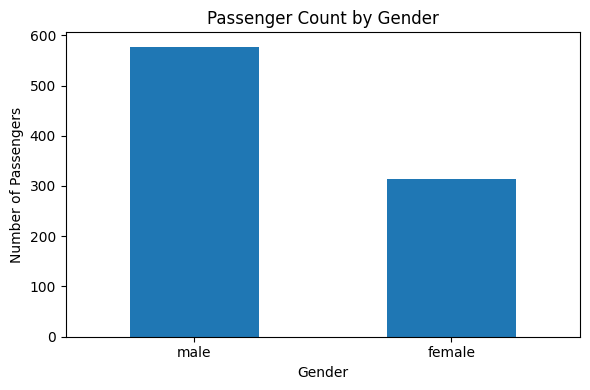

In [7]:
gender_counts = cleaned_df["Sex"].value_counts()

plt.figure(figsize=(6, 4))
gender_counts.plot(kind="bar")
plt.title("Passenger Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7.2 Age distribution

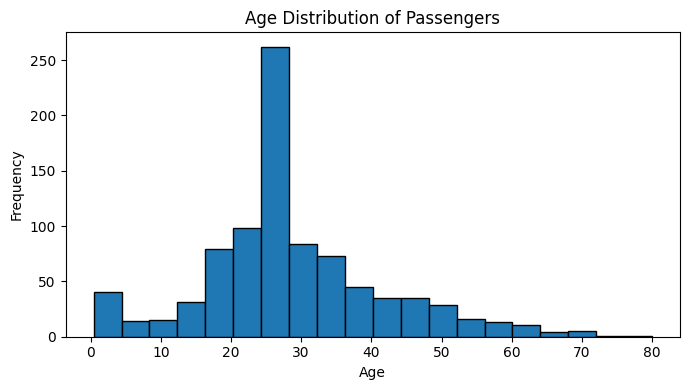

In [8]:
plt.figure(figsize=(7, 4))
plt.hist(cleaned_df["Age"], bins=20, edgecolor="black")
plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 7.3 Survival count

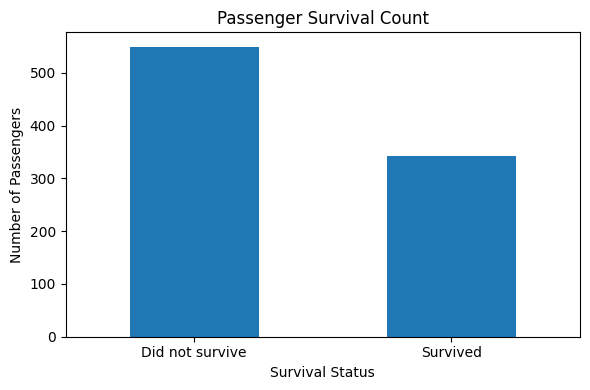

In [9]:
survival_labels = cleaned_df["Survived"].map({0: "Did not survive", 1: "Survived"})
survival_counts = survival_labels.value_counts()

plt.figure(figsize=(6, 4))
survival_counts.plot(kind="bar")
plt.title("Passenger Survival Count")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7.4 Fare distribution

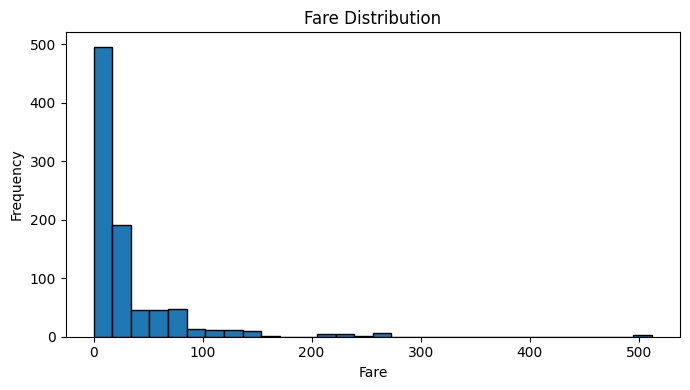

In [10]:
plt.figure(figsize=(7, 4))
plt.hist(cleaned_df["Fare"], bins=30, edgecolor="black")
plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 7.5 Fare outlier box plot

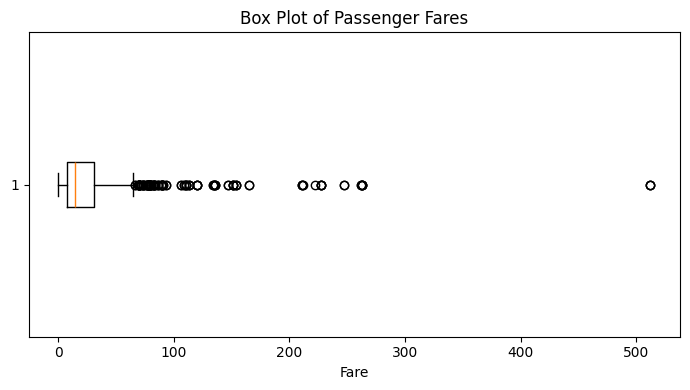

In [11]:
plt.figure(figsize=(7, 4))
plt.boxplot(cleaned_df["Fare"], vert=False)
plt.title("Box Plot of Passenger Fares")
plt.xlabel("Fare")
plt.tight_layout()
plt.show()

## 8. Save the cleaned dataset

In [12]:
cleaned_file = OUTPUT_DIR / "cleaned_titanic.csv"
cleaned_df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved to:", cleaned_file)
print("Cleaned dataset shape:", cleaned_df.shape)

Cleaned dataset saved to: /mnt/data/output/cleaned_titanic.csv
Cleaned dataset shape: (891, 12)


## 9. Summary

In this project, the Titanic dataset was loaded and explored using Pandas. Missing values in selected columns were handled, duplicate rows were removed, and potential fare outliers were identified using the IQR method. Matplotlib charts were created to explore passenger gender, age, survival, and fare distributions.

**Output:** `output/cleaned_titanic.csv`

### Note
This is an exploratory data cleaning and visualization project. It does not train a machine-learning model or make predictions.